In [ ]:
# @title


import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline


def alpha_sot(y):
  return 1/(1 + np.exp(-y))
def density_ratio_sot(y):
  return 1/(2*alpha_sot(y))
def generate_s(p):
  s = []
  for i in p:
    response = np.random.binomial(n=1, p=alpha_sot(i), size=1)
    if response:
      s.append(i)
  return s
def density_ratio_estimator(s_1):
  s_0 = generate_s(p_0)
  X_train = np.concatenate([p_0, s_0]).reshape(-1, 1)
  y_train = np.concatenate([np.ones(len(p_0)), np.zeros(len(s_0))])
  clf = LogisticRegression(solver='lbfgs')
  clf = make_pipeline(PolynomialFeatures(degree=3), LogisticRegression(solver='lbfgs'))
  clf.fit(X_train, y_train)
  probs = clf.predict_proba(np.array(s_1).reshape(-1, 1))
  return probs[:, 1], len(p_0), len(s_0)
def theta_estimator(s_1):
  numerator = 0
  denominator = 0
  d_ratio = density_ratio_estimator(s_1)
  for i in range(len(s_1)):
    numerator+= (s_1[i]*density_ratio_sot(s_1[i]) )
    denominator += density_ratio_sot(s_1[i])
  return numerator/denominator
def theta_estimator_classifier(s_1):
  numerator = 0
  denominator = 0
  d_ratio, length_p_0, length_s_0 = density_ratio_estimator(s_1)
  for i in range(len(s_1)):
    numerator+= (s_1[i]*(length_s_0 / length_p_0)*(d_ratio[i]/(1 - d_ratio[i])) )
    denominator += (length_s_0 / length_p_0)*(d_ratio[i]/(1 - d_ratio[i]))
  return numerator/denominator


n = 100000
p_0 = np.random.normal(0, 1, n)
p_1 = np.random.normal(0.5, 1, n)
s_1 = generate_s(p_1)

print(theta_estimator(s_1))
print(theta_estimator_classifier(s_1))


0.503374853346633
0.5023070586782818


In [ ]:
# @title
import matplotlib.pyplot as plt

def run_experiment(n_pop, p0, p1):
    # 1. Generate Data
    s0 = np.array(generate_s(p0))
    s1 = np.array(generate_s(p1))

    # 2. Oracle Estimator
    weights_sot = density_ratio_sot(s1)
    theta_sot = np.sum(s1 * weights_sot) / np.sum(weights_sot)

    # 3. Classifier Pipeline
    X_train = np.concatenate([p0, s0]).reshape(-1, 1)
    y_train = np.concatenate([np.ones(len(p0)), np.zeros(len(s0))])

    clf = make_pipeline(PolynomialFeatures(degree=3), LogisticRegression(solver='lbfgs'))
    clf.fit(X_train, y_train)

    probs = clf.predict_proba(s1.reshape(-1, 1))[:, 1]
    odds = probs / (1 - probs + 1e-10)
    weights_clf = odds * (len(s0) / len(p0))
    theta_clf = np.sum(s1 * weights_clf) / np.sum(weights_clf)


    return  theta_sot, theta_clf, s1, weights_clf, p1
n = 100000
p0 = np.random.normal(0, 1, n)
p1 = np.random.normal(0.5, 1, n)

sot, clf_est, _, _, _ = run_experiment(n, p0, p1)

plt.figure(figsize=(8, 5))
plt.bar(['Classifier', 'Oracle'], [clf_est, sot], color=[ 'blue', 'green'])
plt.axhline(0.5, color='black', linestyle='--', label='True Mean (0.5)')
plt.ylabel('Estimated Mean')
plt.title('Estimator Accuracy Comparison')
plt.legend()
plt.show()


_, _, s1, weights, p1 = run_experiment(100000, p0, p1)

# Weighted resample for visualization
weighted_s1 = np.random.choice(s1, size=len(s1), p=weights/np.sum(weights))

plt.figure(figsize=(10, 6))
# Using hist to represent the distributions
plt.hist(p1, bins=50, density=True, alpha=0.3, label='Target P1 (Truth)', color='black')
plt.hist(s1, bins=50, density=True, alpha=0.3, label='Raw Survey S1 (Biased)', color='red')
plt.hist(weighted_s1, bins=50, density=True, alpha=0.3, label='Weighted Survey S1', color='blue')
plt.title('Distribution Alignment (Bias Correction)')
plt.legend()
plt.show()


sizes = [1000, 5000, 10000, 50000, 100000]
errors = []

for n_size in sizes:
    p0_sub = np.random.normal(0, 1, n_size)
    p1_sub = np.random.normal(0.5, 1, n_size)
    _, clf_est, _, _, _ = run_experiment(n_size, p0_sub, p1_sub)
    errors.append(abs(clf_est - 0.5))

plt.figure(figsize=(8, 5))
plt.plot(sizes, errors, marker='o', linestyle='-', color='blue')
plt.xscale('log')
plt.xlabel('Sample Size (log scale)')
plt.ylabel('Absolute Error |Estimator - 0.5|')
plt.title('Convergence: Estimator improves with data')
plt.grid(True)
plt.show()


runs = 5000
estimates = []

for _ in range(runs):
    # Fixed size for stability check
    n_check = 50000
    p0_check = np.random.normal(0, 1, n_check)
    p1_check = np.random.normal(0.5, 1, n_check)
    _, clf_est, _, _, _ = run_experiment(n_check, p0_check, p1_check)
    estimates.append(clf_est)

plt.figure(figsize=(6, 5))
plt.boxplot(estimates, labels=['Classifier Estimator'])
plt.axhline(0.5, color='red', linestyle='--', label='True Mean')
plt.title(f'Stability: Variance over {runs} simulations')
plt.ylabel('Theta Estimate')
plt.legend()
plt.show()


In [ ]:
# @title
import matplotlib.pyplot as plt

# 1. Prepare data for plotting (Subsample to 5,000 points for speed)

s_1 = generate_s(p_1)
s_0 = generate_s(p_0)
d_ratio_sub, _, _ = density_ratio_estimator(s_1)

# Calculate the estimated density ratio weights for the subsample
# w(y) = (N_S0 / N_P0) * (pi / (1 - pi))
estimated_weights = (len(s_0) / len(p_0)) * (d_ratio_sub / (1 - d_ratio_sub ))

# 2. Plot 1: Alpha Estimator vs. True Alpha
plt.figure(figsize=(10, 5))
# The estimated alpha is the inverse of the density ratio weight
alpha_estimator = 1 / (2*estimated_weights)

plt.scatter(s_1, alpha_estimator, alpha=0.3, s=5, label='Classifier Estimated alpha', color='blue')

# Overlay True Alpha Function
y_range = np.linspace(min(s_1), max(s_1), 10000)
plt.plot(y_range, alpha_sot(y_range), color='red', linewidth=3, label='True alpha_sot(y)')

plt.title("Estimated vs. True Response Bias (Alpha)")
plt.xlabel("Y")
plt.ylabel("Alpha")
plt.legend()
plt.show()

# 3. Plot 2: Density Ratio Estimator vs. True Density Ratio
plt.figure(figsize=(10, 5))
plt.scatter(s_1, estimated_weights, alpha=0.3, s=5, label='Classifier Estimated Density Ratio', color='green')

# Overlay True Density Ratio Function
plt.plot(y_range, density_ratio_sot(y_range), color='red', linewidth=3, label='True density_ratio_sot(y)')

plt.title("Estimated vs. True Density Ratio")
plt.xlabel("Y")
plt.ylabel("Weight (Density Ratio)")
plt.legend()
plt.show()

Closed Form estimator: 0.5061178842092505
Classifier estimator: 0.5070973023988656


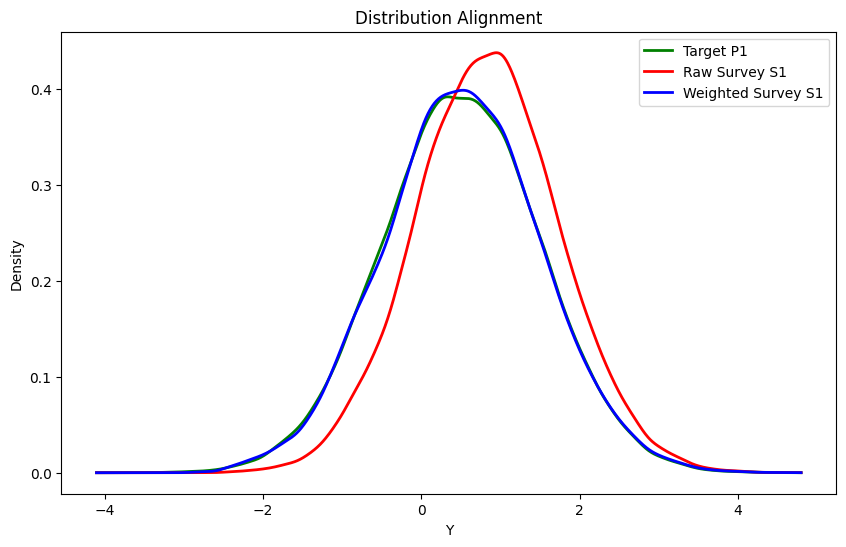

/tmp/ipykernel_3383/4276200966.py:233: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


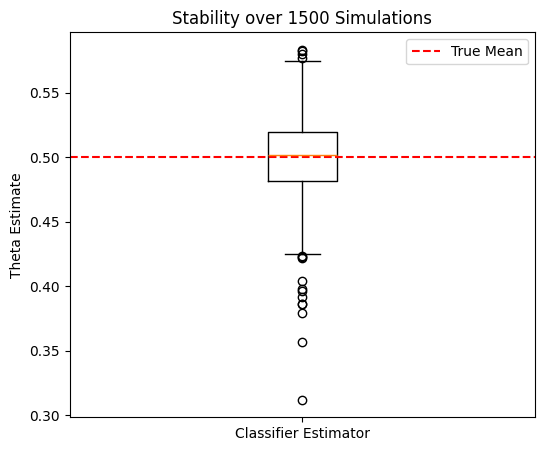

60197 length s1
60197 length estimated_weights
60197 length alpha_estimator


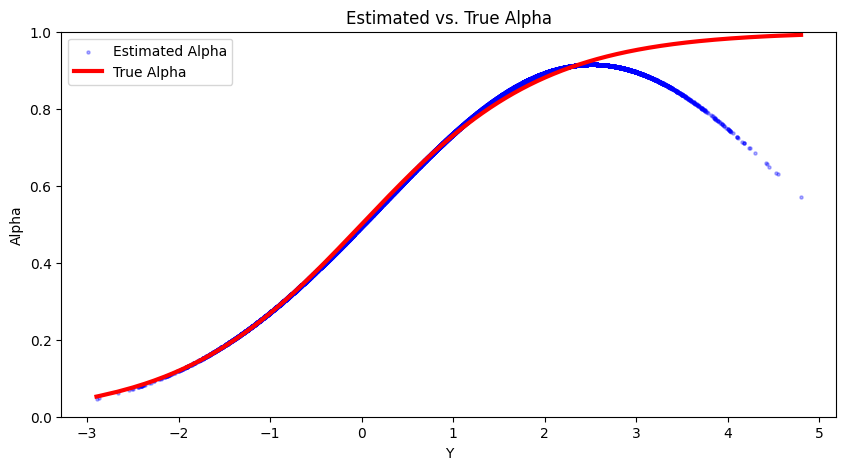

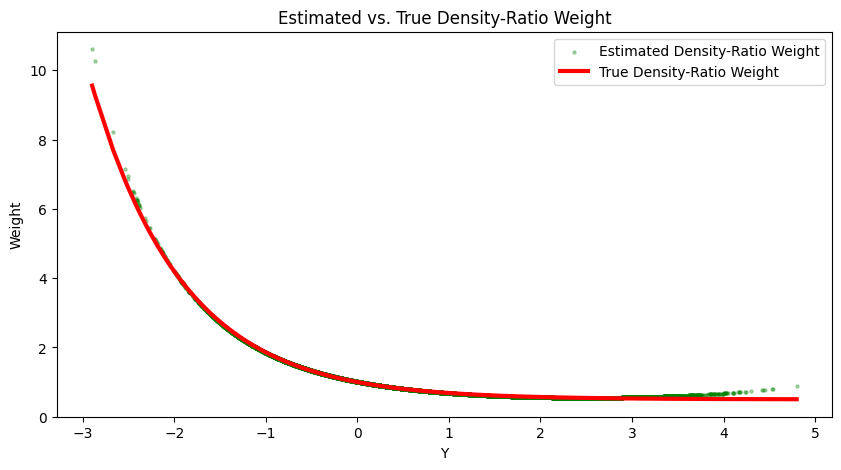

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from scipy.stats import gaussian_kde
import numpy as np
import matplotlib.pyplot as plt


# check custom loss function random forest , via gradient descent , python specify loss function and one paramter, initize and run gradient descent and see where it converges to.
#apply to real data
# Helper functions
# roshni714

#closed form alpha function
def alpha_sot(y):
    return 1 / (1 + np.exp(-y))

#closed form density ratio based off of chosen p_t, s_t distributions and alpha
def density_ratio_sot(y):
    # f_P0(y) / f_S0(y)
    return 1 / (2 * alpha_sot(y))

#general s_t using bernoulli distribution where probability of chosen is determined by alpha. Our chosen value of alpha increases as y increases
def generate_s(p):
    s = []

    for i in p:
        response = np.random.binomial(
            n=1,
            p=alpha_sot(i)
        )

        if response == 1:
            s.append(i)

    return np.array(s)

#estimates density ratio using probabilistic classifier
def density_ratio_estimator(s_1, p0=None):
    if p0 is None:
        p0 = p_0

    s_0 = generate_s(p0)
    # s_0 and p_0 independent , shouldnt be passing p_0 into the generate s_0
    #same number of sample of s and p
    # class imbalance
    X_train = np.concatenate([
        p0,
        s_0
    ]).reshape(-1, 1)

    # 1 means P0; 0 means S0
    y_train = np.concatenate([
        np.ones(len(p0)),
        np.zeros(len(s_0))
    ])

    clf = make_pipeline(
        PolynomialFeatures(
            degree=3,
            include_bias=False
        ),
        LogisticRegression(
            solver="lbfgs",
            max_iter=1000
        )
    )

    clf.fit(X_train, y_train)

    probs = clf.predict_proba(
        np.array(s_1).reshape(-1, 1)
    )[:, 1]

    return probs, len(p0), len(s_0)

# estimates the target population using the closed form density ratio
def theta_estimator(s_1):
    numerator = 0
    denominator = 0

    for i in range(len(s_1)):
        weight = density_ratio_sot(s_1[i])

        numerator += s_1[i] * weight
        denominator += weight

    return numerator / denominator

# estimates the target population using the closed form classifier
# look into scaling ratio for imbalance class
def theta_estimator_classifier(s_1, p0=None):
    numerator = 0
    denominator = 0

    probs, length_p_0, length_s_0 = density_ratio_estimator(
        s_1,
        p0
    )
    weights = (
        length_s_0 / length_p_0
    ) * (
        probs / (1 - probs)
    )

    for i in range(len(s_1)):
        numerator += s_1[i] * weights[i]
        denominator += weights[i]

    return numerator / denominator

#master function to run inputs for visuals
def run_experiment(n_pop, p0, p1):
    s1 = generate_s(p1)

    theta_sot = theta_estimator(s1)

    probs, length_p_0, length_s_0 = density_ratio_estimator(
        s1,
        p0
    )
    weights_clf = (
        length_s_0 / length_p_0
    ) * (
        probs / (1 - probs)
    )

    theta_clf = (
        np.sum(s1 * weights_clf)
        / np.sum(weights_clf)
    )

    return theta_sot, theta_clf, s1, weights_clf, p1



# Generate data


np.random.seed(123)

n = 100000

p_0 = np.random.normal(0, 1, n)
p_1 = np.random.normal(0.5, 1, n)
s_1 = generate_s(p_1)

print("Closed Form estimator:", theta_estimator(s_1))
print(
    "Classifier estimator:",
    theta_estimator_classifier(s_1, p_0)
)



# Distribution shift graph

_, _, s1, weights, p1 = run_experiment(
    n,
    p_0,
    p_1
)

# Grid for plotting densities
x_grid = np.linspace(
    min(np.min(p1), np.min(s1)),
    max(np.max(p1), np.max(s1)),
    1000
)

# KDEs
kde_p1 = gaussian_kde(p1)
kde_s1 = gaussian_kde(s1)
kde_weighted_s1 = gaussian_kde(s1, weights=weights)

plt.figure(figsize=(10, 6))

plt.plot(
    x_grid,
    kde_p1(x_grid),
    label="Target P1",
    color="green",
    linewidth=2
)

plt.plot(
    x_grid,
    kde_s1(x_grid),
    label="Raw Survey S1",
    color="red",
    linewidth=2
)

plt.plot(
    x_grid,
    kde_weighted_s1(x_grid),
    label="Weighted Survey S1",
    color="blue",
    linewidth=2
)

plt.title("Distribution Alignment")
plt.xlabel("Y")
plt.ylabel("Density")
plt.legend()
plt.show()





# Stability graph


runs = 1500
estimates = []

for _ in range(runs):
    n_check = 5000

    p0_check = np.random.normal(0, 1, n_check)
    p1_check = np.random.normal(0.5, 1, n_check)

    _, clf_est, _, _, _ = run_experiment(
        n_check,
        p0_check,
        p1_check
    )

    estimates.append(clf_est)

plt.figure(figsize=(6, 5))

plt.boxplot(
    estimates,
    labels=["Classifier Estimator"]
)

plt.axhline(
    0.5,
    color="red",
    linestyle="--",
    label="True Mean"
)

plt.title(f"Stability over {runs} Simulations")
plt.ylabel("Theta Estimate")
plt.legend()
plt.show()



# Estimated alpha and weights


s_1 = generate_s(p_1)
sort_idx = np.argsort(s_1)
s_1_sorted = s_1[sort_idx]

probs, length_p_0, length_s_0 = density_ratio_estimator(
    s_1,
    p_0
)
print(len(s_1), "length s1")

estimated_weights = (
    length_s_0 / length_p_0
) * (
    probs / (1 - probs)
)

print(len(estimated_weights), "length estimated_weights")

# Since w(y) = 1 / (2 alpha(y))
alpha_estimator = 1 / (2 * estimated_weights)


print(len(alpha_estimator), "length alpha_estimator")


plt.figure(figsize=(10, 5))

plt.scatter(
    s_1,
    alpha_estimator,
    alpha=0.3,
    s=5,
    label="Estimated Alpha",
    color="blue"
)

plt.plot(
    s_1_sorted,
    alpha_sot(s_1_sorted),
    color="red",
    linewidth=3,
    label="True Alpha"
)

plt.ylim(0, 1)
plt.title("Estimated vs. True Alpha")
plt.xlabel("Y")
plt.ylabel("Alpha")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))

plt.scatter(
    s_1,
    estimated_weights,
    alpha=0.3,
    s=5,
    label="Estimated Density-Ratio Weight",
    color="green"
)

plt.plot(
    s_1_sorted,
    density_ratio_sot(s_1_sorted),
    color="red",
    linewidth=3,
    label="True Density-Ratio Weight"
)

plt.title("Estimated vs. True Density-Ratio Weight")
plt.xlabel("Y")
plt.ylabel("Weight")
plt.legend()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from scipy.stats import gaussian_kde
import numpy as np
import matplotlib.pyplot as plt



# Helper functions

#closed form alpha function
def alpha_sot(y):
    return 1 / (1 + np.exp(-y))

#closed form density ratio based off of chosen p_t, s_t distributions and alpha
def density_ratio_sot(y):
    # f_P0(y) / f_S0(y)
    return 1 / (2 * alpha_sot(y))

#general s_t using bernoulli distribution where probability of chosen is determined by alpha. Our chosen value of alpha increases as y increases
def generate_s(p):
    s = []

    for i in p:
        response = np.random.binomial(
            n=1,
            p=alpha_sot(i)
        )

        if response == 1:
            s.append(i)

    return np.array(s)

# Generate data


np.random.seed(123)

n = 100000

p_0 = np.random.normal(0, 1, n)
p_1 = np.random.normal(0.5, 1, n)
#s_1 = generate_s(p_1)

In [ ]:
print(len(p_1))
len(generate_s(p_1))

100000
60200


deviation at right tails of the y (large values of y) indicates a classication error for larger values of y

The raw respondent distribution S_1 is shifted toward larger outcomes because response probability increases with Y. Reweighting S_1 using the estimated historical inverse density ratio aligns the weighted respondent distribution with the current target population P_1. Both the closed-form and classifier-based estimators recover the target mean closely.